# Phase 4 — Data Integration

Integrates the selected crops' (Onion, Potato, Wheat) mandi price/arrivals records with APY production statistics, the Phase 3 weather series, the `final_data.csv` market reference and the regional Agri Market dataset — each at its own verified grain, with every join's cardinality and row counts checked. The implementation lives in `Code/integration/pipeline.py`; this notebook runs it and explains the decisions and results.

## INDEX

1. [Objective and Scope](#1)
2. [Inputs and Dependencies](#2)
3. [Source-Schema Audit](#3)
4. [Geographic Alignment Decisions](#4)
5. [Temporal Alignment Decisions](#5)
6. [Integration Methodology and Output Grains](#6)
7. [Run the Integration Pipeline](#7)
8. [Row Counts and Join Coverage](#8)
9. [Crop-wise Integration Summaries](#9)
10. [Validation Checks](#10)
11. [Coverage Charts](#11)
12. [Interpretation](#12)
13. [Limitations and Unresolved Issues](#13)
14. [Completion Summary and Phase 5 Handoff](#14)


<a id="1"></a>
## 1. Objective and Scope

**Objective**: build the integrated data foundation for later phases — standardized keys, documented geographic and temporal alignment, and audited joins — without fabricating or silently dropping anything.

**In scope**: minimum type normalization and safe parsing needed to join (column names, dates, categorical keys), geographic/temporal key alignment, joins, and integration audits.

**Out of scope** (later phases): cleaning of anomalies such as zero prices, min>max rows or duplicate records (Phase 5 — they are *flagged* here, not fixed), feature engineering (6), formal EDA (7), models (8–10), Dijkstra (11), MILP (12).

`Arrivals (Tonnes)` is treated throughout as a **supply-side market-activity proxy, not consumer demand** (Assumption A-02).

<a id="2"></a>
## 2. Inputs and Dependencies

| Input | Role | Produced by |
|---|---|---|
| `Dataset/India Commodity Wise Mandi Dataset/{Onion,Potato,Wheat}.csv` | daily price + arrivals per market | raw (read-only) |
| `Dataset/crop-wise-area-production-yield.csv` (+ codebook) | district/season/agricultural-year production | raw (read-only) |
| `Dataset/Agri Market Dataset.csv` | Wheat regional cross-check (Maharashtra, Amravati division) | raw (read-only) |
| `Dataset/final_data.csv` | State/District/Market code reference | raw (read-only) |
| `Processed_Data/selected_crops.csv` | crop scope | Phase 2 |
| `Processed_Data/weather/weather_location_mapping.csv`, `raw/*.csv` | 46 representative locations, daily weather 2001–2022 | Phase 3 |
| `Code/integration/district_aliases.csv` | reviewed mandi→APY district name crosswalk | **Phase 4 (new)** |
| `Processed_Data/integration/geocoder_evidence_phase4.csv` | every geocoder candidate returned for the 46 locations (evidence) | **Phase 4 (new)** |

In [1]:
import os, sys, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.append(str(PROJECT_ROOT))
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

from Code.integration import pipeline as p
from Code.weather.config import DAILY_VARIABLES

CROPS = p.load_selected_crops()
FIG = Path("Outputs/Figures")
print("Selected crops:", CROPS)
for path in p.source_paths(CROPS)[:9]:
    print(f"{'OK ' if path.exists() else 'MISSING'} {path}")

Selected crops: ['Onion', 'Potato', 'Wheat']
OK  Dataset\India Commodity Wise Mandi Dataset\Onion.csv
OK  Dataset\India Commodity Wise Mandi Dataset\Potato.csv
OK  Dataset\India Commodity Wise Mandi Dataset\Wheat.csv
OK  Dataset\crop-wise-area-production-yield.csv
OK  Dataset\Agri Market Dataset.csv
OK  Dataset\final_data.csv
OK  Processed_Data\weather\weather_location_mapping.csv
OK  Processed_Data\selected_crops.csv
OK  Processed_Data\weather\raw\Gujarat_Amreli.csv


<a id="3"></a>
## 3. Source-Schema Audit

Schemas, units and candidate keys of each source. Only small samples are read here; the mandi files (~2.6 M rows each) are processed one crop at a time inside the pipeline with categorical text columns, never all at once.

In [2]:
rows = []
for crop in CROPS:
    s = pd.read_csv(p.MANDI_DIR / f"{crop}.csv", nrows=1000)
    rows += [{"source": f"mandi/{crop}.csv", "raw_column": c, "dtype": str(s[c].dtype),
              "canonical_column": p.MANDI_COLUMNS.get(c, "-"), "example": s[c].iloc[0]} for c in s.columns]
apy_sample = pd.read_csv(p.APY_PATH, nrows=1000)
rows += [{"source": "APY", "raw_column": c, "dtype": str(apy_sample[c].dtype),
          "canonical_column": p.APY_COLUMNS.get(c, "unit column (constant, checked then dropped)"),
          "example": apy_sample[c].iloc[0]} for c in apy_sample.columns if c != "id"]
schema = pd.DataFrame(rows)
schema[schema["source"].isin(["mandi/Onion.csv", "APY"])]

,source,raw_column,dtype,canonical_column,example
0,mandi/Onion.csv,State Name,object,state,Arunachal Pradesh
1,mandi/Onion.csv,District Name,object,district,Tawang
2,mandi/Onion.csv,Market Name,object,market,Tawang
3,mandi/Onion.csv,Variety,object,variety,Other
4,mandi/Onion.csv,Group,object,commodity_group,Vegetables
5,mandi/Onion.csv,Arrivals (Tonnes),float64,arrivals_tonnes,0.9
6,mandi/Onion.csv,Min Price (Rs./Quintal),float64,min_price_rs_per_quintal,1200.0
7,mandi/Onion.csv,Max Price (Rs./Quintal),float64,max_price_rs_per_quintal,1600.0
8,mandi/Onion.csv,Modal Price (Rs./Quintal),float64,modal_price_rs_per_quintal,1500.0
9,mandi/Onion.csv,Reported Date,object,reported_date,09 Feb 2006


**Units**: mandi arrivals in tonnes and prices in Rs./quintal (kept in the canonical names `arrivals_tonnes`, `*_price_rs_per_quintal`); APY area in hectares, production in tonnes, yield in tonnes/hectare (the pipeline asserts each unit column holds only that single value before dropping it into `area_ha`, `production_tonnes`, `yield_t_per_ha`). Onion, Potato and Wheat files share the identical 10-column schema; all dates are `DD Mon YYYY`.

**Key uniqueness checks** on the reference sources:

In [3]:
apy = pd.read_csv(p.APY_PATH)
apy3 = apy[apy["crop_name"].isin(CROPS)]
fd = pd.read_csv(p.MARKET_REF_PATH)
am = pd.read_csv(p.AGRI_MARKET_PATH)
amw = am[am["Commodity"] == "Wheat"]
key_checks = pd.DataFrame([
    {"source": "APY (3 crops)", "key": "crop, state, district, year, season", "rows": len(apy3),
     "duplicate_key_rows": int(apy3.duplicated(["crop_name", "state_name", "district_name", "year", "season"]).sum())},
    {"source": "final_data.csv", "key": "Market_code", "rows": len(fd),
     "duplicate_key_rows": int(fd["Market_code"].duplicated().sum())},
    {"source": "final_data.csv", "key": "State, District, Market", "rows": len(fd),
     "duplicate_key_rows": int(fd.duplicated(["State", "District", "Market"]).sum())},
    {"source": "Agri Market (Wheat)", "key": "Market, Date", "rows": len(amw),
     "duplicate_key_rows": int(amw.duplicated(["Market Name", "Reported Date"]).sum())},
    {"source": "Agri Market (Wheat)", "key": "Market, Variety, Date", "rows": len(amw),
     "duplicate_key_rows": int(amw.duplicated(["Market Name", "Variety", "Reported Date"]).sum())},
])
print("APY year values:", sorted(apy3["year"].unique())[:3], "...", sorted(apy3["year"].unique())[-2:])
print("APY seasons:", apy3["season"].value_counts().to_dict())
key_checks

APY year values: ['1997-1998', '1998-1999', '1999-2000'] ... ['2021-2022', '2022-2023']
APY seasons: {'Rabi': 20146, 'Whole Year': 11233, 'Total': 4142, 'Kharif': 2742, 'Summer': 2346, 'Winter': 1216, 'Autumn': 10}


,source,key,rows,duplicate_key_rows
0,APY (3 crops),"crop, state, district, year, season",41835,0
1,final_data.csv,Market_code,4151,0
2,final_data.csv,"State, District, Market",4151,11
3,Agri Market (Wheat),"Market, Date",9569,1085
4,Agri Market (Wheat),"Market, Variety, Date",9569,0


Findings that shape the design:

- **APY** is unique at *(crop, state, district, year, season)*. Its `year` is an agricultural-year label (`1997-1998` … `2022-2023`). APY also publishes a **`Total` season row equal to the sum of the other seasons** (verified on 99.9% of district-years during this phase), so seasons must never be summed together with `Total`.
- **`final_data.csv`**: `Market_code` is unique, but 11 *(State, District, Market)* name pairs appear twice with different codes — those markets are left uncoded (ambiguous), not resolved by picking one.
- **Agri Market Wheat** is not unique on *(market, date)* (several varieties per day) but is unique on *(market, variety, date)* — that is its grain.
- **Mandi** records are mostly unique on *(state, district, market, variety, group, date)*; the duplicates are quantified in Section 9 and *flagged*, not dropped.

<a id="4"></a>
## 4. Geographic Alignment Decisions

### 4a. Weather locations — verification and resolution of the 10 unresolved

Phase 3 accepted a geocoder result when its state (`admin1`) matched. Phase 4 adds a stricter, documented rule, applied to **all 46** representative locations:

> Accept a geocoder candidate only if `admin1` equals the state **and** `admin2` (the geocoder's district) equals the mandi district name, its official APY (DES) district name, or a documented equivalent (e.g. *Alleppey* = Alappuzha). Prefer district seats (`PPLA/PPLA2`), then population.

Alternative search terms (the official APY spelling, or the district headquarters town) are only search keys — acceptance always depends on the `admin1`/`admin2` evidence, which is stored in `geocoder_evidence_phase4.csv`.

In [4]:
res = pd.read_csv("Processed_Data/integration/weather_location_resolution.csv") if Path(
    "Processed_Data/integration/weather_location_resolution.csv").exists() else None
print("(resolution table is (re)built by the pipeline in Section 7; shown here from the last run if present)")
if res is not None:
    display(res.loc[res["resolution_status"] != "phase3_verified",
                    ["state", "district", "phase3_status", "resolution_status", "geocoder_query", "geocoder_name",
                     "geocoder_admin2", "latitude", "longitude", "phase3_point_admin2", "correction_distance_km"]])

(resolution table is (re)built by the pipeline in Section 7; shown here from the last run if present)


,state,district,phase3_status,resolution_status,geocoder_query,geocoder_name,geocoder_admin2,latitude,longitude,phase3_point_admin2,correction_distance_km
7,Punjab,Bhatinda,unresolved,phase4_resolved_alias,Bathinda,Bathinda,Bathinda,30.20747,74.93893,NaN,NaN
8,Uttar Pradesh,Bulandshahar,unresolved,phase4_resolved_alias,Bulandshahr,Bulandshahr,Bulandshahr district,28.40392,77.85773,NaN,NaN
11,Kerala,Palakad,unresolved,phase4_resolved_alias,Palakkad,Palakkad,Palakkad,10.77319,76.65366,NaN,NaN
14,Maharashtra,Ahmednagar,unresolved,phase4_resolved_alias,Ahilyanagar,Ahilyanagar,Ahmednagar,19.09457,74.73843,NaN,NaN
17,Punjab,Ferozpur,mapped,phase3_rejected_corrected,Ferozepur,Firozpur,Firozpur,30.92574,74.61311,Narowal District,159.2
22,West Bengal,Coochbehar,unresolved,phase4_resolved_alias,Cooch Behar,Koch Bihār,Cooch Behar,26.32539,89.44508,NaN,NaN
28,Rajasthan,Ganganagar,unresolved,phase4_resolved_alias,Sri Ganganagar,Sri Ganganagar,Ganganagar,29.92009,73.87496,NaN,NaN
29,Gujarat,Sabarkantha,unresolved,phase4_resolved_alias,Himatnagar,Himatnagar,Sabar Kantha,23.59893,72.96602,NaN,NaN
37,Maharashtra,Buldhana,unresolved,phase4_resolved_alias,Buldana,Buldāna,Buldhana,20.52933,76.18457,NaN,NaN
44,Gujarat,Banaskanth,unresolved,phase4_resolved_alias,Palanpur,Pālanpur,Banas Kantha,24.17128,72.43827,NaN,NaN


- **10 of 10 previously unresolved locations are now resolved** with admin2-confirmed coordinates (e.g. Bhatinda → *Bathinda*, admin2 Bathinda; Sabarkantha → *Himatnagar*, a district seat whose admin2 is Sabar Kantha).
- **One Phase 3 mapping was wrong and is corrected**: Phase 3's "Ferozpur" point (*Ferozpura*, 32.30 N 75.07 E) has `admin2 = Narowal District` — not Firozpur district. The admin2-confirmed *Firozpur* (30.93 N 74.61 E) is ~159 km away. Its weather was re-collected into a **new** cache file (`Punjab_Ferozpur_corrected.csv`); the Phase 3 file is left untouched but no longer used.
- The other 35 Phase 3 coordinates passed the stricter rule unchanged.

### 4b. Mandi → weather association rule

| Option | Evaluation | Decision |
|---|---|---|
| Exact *(state, district)* match to a verified location | Precise; uses only verified coordinates | **Adopted** |
| Same-state nearest verified location | Needs a verified coordinate for *every* unmapped mandi district (≈470 per crop) to compute "nearest", plus an evidence-based distance threshold. Neither exists; geocoding hundreds of districts is new collection work. | **Not adopted in Phase 4** (no proxy matches assigned) |
| Keep unmatched records, weather missing | Honest; preserves all records | **Adopted for everything not exactly matched** |

Every mandi row keeps its original `state`/`district`; the weather source is identifiable via `weather_state`, `weather_district` and `weather_location_method`.

### 4c. Mandi → APY district crosswalk

APY uses official (DES) district names; mandi names are often older spellings. Matching order: (1) a **reviewed alias table** (`Code/integration/district_aliases.csv`, 131 rows, each with a stated basis — spelling variant, official rename, or headquarters-town name; 9 are explicit exclusions), (2) exact normalized name, (3) a unique match on a parenthetical part (*Ropar (Rupnagar)* → Rupnagar). **No fuzzy similarity is auto-accepted.** Districts that were split (Burdwan, Kanpur, Bangalore, Tripura's 2012 reorganisation) or urban districts with no APY rows are deliberately left unmatched. The pipeline fails loudly if an alias target does not exist in APY.

<a id="5"></a>
## 5. Temporal Alignment Decisions

- **Mandi ↔ weather**: both are daily calendar dates → joined on the **same day** (`reported_date`). Weather covers 2001-01-01 to 2022-12-31; mandi records outside that window keep missing weather and are labelled `exact_district_outside_weather_window`.
- **Mandi ↔ APY**: APY's `year` (e.g. `2022-2023`) is an Indian **agricultural year, July–June** (Assumption A-13). Each mandi record gets `apy_year` = the agricultural year containing its date (2022-07-01 … 2023-06-30 → `2022-2023`) and `apy_year_lag1` = the previous agricultural year. The original APY label is preserved; **no APY year is converted into a single date**.
- **No repetition of annual values onto daily rows**: the mandi tables only carry the *keys* (`apy_state`, `apy_district`, `apy_year`) and an `apy_annual_available` flag. APY values are joined to mandi only after aggregating mandi to APY's own grain (`mandi_apy_district_year.csv`, a validated 1:1 join).
- **Leakage**: same-year APY figures are only published after the year ends, so they are not knowable at a record's date. `apy_year_lag1` is the earliest leakage-safe reference; real publication lag is longer (the APY file covering 2022-23 was last updated 14-12-2023), so Phase 6 must choose the lag explicitly. Same-day weather is a contemporaneous observation; forecasting features must lag it too.
- **Caveat**: the July–June mapping is definitional — stored Rabi produce sold after June is labelled with the *next* agricultural year. It is a calendar key, not a claim about which harvest a consignment came from.

<a id="6"></a>
## 6. Integration Methodology and Output Grains

Grains were fixed *before* merging; every join is `pandas.merge(..., validate=...)` with a before/after row-count assertion and a `merge_log.csv` entry.

| Output (`Processed_Data/integration/`) | Grain (unique key) | Join cardinality |
|---|---|---|
| `mandi_integrated_<crop>.parquet` | one row per raw mandi record (`source_row` = 0-based row in the CSV) | left, m:1 to crosswalk, APY-availability keys, market reference, weather location, weather panel |
| `weather_daily_panel.parquet` | (weather_state, weather_district, date) | — |
| `weather_location_resolution.csv` | (state, district), 46 rows | — |
| `apy_season.csv` | (crop, state, district, apy_year, season) | — |
| `apy_annual.csv` | (crop, state, district, apy_year): `Total` row, else single season row, else left missing (`ambiguous_multi_season_no_total`) | — |
| `mandi_apy_district_year.csv` | (crop, apy_state, apy_district, apy_year) | outer, 1:1 |
| `district_crosswalk.csv` | (crop, mandi state, mandi district) | — |
| `agrimarket_wheat_crosscheck.csv` | (district, market, variety, date) of Agri Market Wheat | left, 1:1 against unique mandi keys |
| `audit/*.csv` | merge log, coverage, unmatched keys, duplicates, fingerprints, output manifest | — |

Weather values in the mandi tables repeat for all markets of one district-day; they are the same observation, so any weather analysis should use `weather_daily_panel.parquet`, not the record-level table.

<a id="7"></a>
## 7. Run the Integration Pipeline

Reads only from `Dataset/` and Phase 2/3 outputs, writes only to `Processed_Data/integration/`. Geocoder evidence and resolved-location weather are cached, so re-runs make no network calls. SHA-256 fingerprints of every source file are taken before and after the run.

In [5]:
import logging
logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)
result = p.run_pipeline()
print("\nRun time (s):", result["seconds"])

Decision: crops in scope = ['Onion', 'Potato', 'Wheat'] (Phase 2 selection)


APY season rows=41835, annual rows=33011; annual_method counts={'single_season': 28851, 'total_row': 4142, 'ambiguous_multi_season_no_total': 18}


Weather locations: {'phase3_verified': 35, 'phase4_resolved_alias': 10, 'phase3_rejected_corrected': 1}


merge Onion: mandi x district_crosswalk             left m:1 left=2624379 right=512 -> 2624379


merge Onion: mandi x apy_annual (availability flag) left m:1 left=2624379 right=9498 -> 2624379


...

merge Wheat: mandi x weather_daily_panel (same day) left m:1 left=2593767 right=369610 -> 2593767


merge mandi_district_year x apy_annual              outer 1:1 left=20530 right=33011 -> 38700


merge Wheat: agri_market x mandi (district, market, variety, date) left 1:1 left=9569 right=80656 -> 9569


Phase 4 pipeline finished in 55.0s



Run time (s): 55.0


<a id="8"></a>
## 8. Row Counts and Join Coverage

### 8a. Every merge, before and after

In [6]:
result["merge_log"]

,step,how,validate,keys,left_rows,right_rows,result_rows
0,Onion: mandi x district_crosswalk,left,m:1,"state,district",2624379,512,2624379
1,Onion: mandi x apy_annual (availability flag),left,m:1,"apy_state,apy_district,apy_year",2624379,9498,2624379
2,Onion: mandi x final_data market reference,left,m:1,"state,district,market",2624379,1732,2624379
3,Onion: mandi x weather_location (exact state+d...,left,m:1,"state,district",2624379,46,2624379
4,Onion: mandi x weather_daily_panel (same day),left,m:1,"weather_state,weather_district,reported_date",2624379,369610,2624379
5,Potato: mandi x district_crosswalk,left,m:1,"state,district",2764987,505,2764987
6,Potato: mandi x apy_annual (availability flag),left,m:1,"apy_state,apy_district,apy_year",2764987,10592,2764987
7,Potato: mandi x final_data market reference,left,m:1,"state,district,market",2764987,1624,2764987
8,Potato: mandi x weather_location (exact state+...,left,m:1,"state,district",2764987,46,2764987
9,Potato: mandi x weather_daily_panel (same day),left,m:1,"weather_state,weather_district,reported_date",2764987,369610,2764987


Every left join kept the left row count exactly (m:1 or 1:1 enforced by pandas; a violation would have raised `IntegrationError`). The only outer join (mandi district-year × APY annual) is 1:1 and its result size equals the union of both key sets.

### 8b. Output manifest (rows and grain of each file, re-opened from disk)

In [7]:
result["manifest"].drop(columns="content_sha256")

,file,grain,rows,columns
0,mandi_integrated_onion.parquet,one row per raw mandi record (source_row),2624379,33
1,mandi_integrated_potato.parquet,one row per raw mandi record (source_row),2764987,33
2,mandi_integrated_wheat.parquet,one row per raw mandi record (source_row),2593767,33
3,weather_daily_panel.parquet,"weather_state, weather_district, reported_date",369610,10
4,weather_location_resolution.csv,"state, district",46,20
5,apy_season.csv,"crop, state, district, apy_year, season",41835,12
6,apy_annual.csv,"crop, state, district, apy_year",33011,12
7,mandi_apy_district_year.csv,"crop, apy_state, apy_district, apy_year",38700,21
8,district_crosswalk.csv,"crop, state, district",1474,8
9,agrimarket_wheat_crosscheck.csv,"district, market, variety, reported_date",9569,21


<a id="9"></a>
## 9. Crop-wise Integration Summaries

In [8]:
cov = result["coverage"]
def pivot(dim):
    t = cov[cov["dimension"] == dim].pivot_table(index="value", columns="crop", values="records", aggfunc="sum")
    return t.join((t / t.sum() * 100).round(2).add_suffix(" %"))
print("Weather match (records)"); display(pivot("weather_match"))
print("Weather location method (records with a location)"); display(pivot("weather_location_method"))

Weather match (records)


crop,Onion,Potato,Wheat,Onion %,Potato %,Wheat %
value,,,,,,
exact_district,662584,652529,654301,25.25,23.60,25.23
exact_district_outside_weather_window,59230,51122,44932,2.26,1.85,1.73
no_weather_location,1902565,2061336,1894534,72.50,74.55,73.04


Weather location method (records with a location)


crop,Onion,Potato,Wheat,Onion %,Potato %,Wheat %
value,,,,,,
nan,1902565,2061336,1894534,72.50,74.55,73.04
phase3_rejected_corrected,20501,21366,1726,0.78,0.77,0.07
phase3_verified,588843,568196,485978,22.44,20.55,18.74
phase4_resolved_alias,112470,114089,211529,4.29,4.13,8.16


In [9]:
print("APY district match"); display(pivot("apy_district_match"))
print("APY annual row available for the record's district and agricultural year"); display(pivot("apy_annual_available"))
print("final_data.csv market code"); display(pivot("market_code_status"))

APY district match


crop,Onion,Potato,Wheat,Onion %,Potato %,Wheat %
value,,,,,,
exact_normalized,1883348,2012454,1997068,71.76,72.78,76.99
excluded_by_review,78461,97226,38256,2.99,3.52,1.47
parenthetical_part,56995,48167,35238,2.17,1.74,1.36
reviewed_alias,576662,578879,506919,21.97,20.94,19.54
state_not_in_apy,23269,21510,16253,0.89,0.78,0.63
unmatched,5644,6751,33,0.22,0.24,0.00


APY annual row available for the record's district and agricultural year


crop,Onion,Potato,Wheat,Onion %,Potato %,Wheat %
value,,,,,,
False,1392739,1039849,167875,53.07,37.61,6.47
True,1231640,1725138,2425892,46.93,62.39,93.53


final_data.csv market code


crop,Onion,Potato,Wheat,Onion %,Potato %,Wheat %
value,,,,,,
ambiguous_in_reference,8895,12539,902,0.34,0.45,0.03
unique_match,2611471,2738069,2591219,99.51,99.03,99.90
unmatched,4013,14379,1646,0.15,0.52,0.06


In [10]:
print("Duplicate-key diagnostics (flagged, not dropped)")
display(result["duplicates"])
mandi_apy = result["mandi_apy"]
print("District-year link status (mandi vs APY)")
display(mandi_apy.groupby(["crop", "link_status"]).size().unstack())
print("APY annual-value method"); display(result["apy_annual"].groupby(["crop", "annual_method"]).size().unstack(fill_value=0))

Duplicate-key diagnostics (flagged, not dropped)


,crop,records,rows_unique,rows_exact_duplicate,rows_conflicting,duplicate_key_groups,unparsed_dates,first_date,last_date
0,Onion,2624379,2622895,1416,68,742,0,2000-10-19,2024-02-02
1,Potato,2764987,2763691,1131,165,644,0,2000-10-19,2024-02-02
2,Wheat,2593767,2592688,973,106,538,0,2001-03-16,2024-02-01


District-year link status (mandi vs APY)


C:\Users\aksha_q43exq6\AppData\Local\Temp\ipykernel_6424\1003888891.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(mandi_apy.groupby(["crop", "link_status"]).size().unstack())


link_status,mandi_only,apy_only,mandi_and_apy
crop,,,
Onion,2870,5467,4075
Potato,2227,5984,4644
Wheat,592,6719,6122


APY annual-value method


annual_method,ambiguous_multi_season_no_total,single_season,total_row
crop,,,
Onion,0,7085,2457
Potato,18,8957,1653
Wheat,0,12809,32


In [11]:
unmatched = pd.read_csv("Processed_Data/integration/audit/unmatched_keys.csv")
print("Largest mandi districts without an APY district (by records)")
display(unmatched[unmatched["key_type"] == "apy_district"].groupby("crop").head(5)
        [["crop", "state", "district", "apy_district_match", "records"]])
print("Agri Market Wheat cross-check:")
pd.Series(result["agri_summary"])

Largest mandi districts without an APY district (by records)


,crop,state,district,apy_district_match,records
0,Onion,West Bengal,Burdwan,excluded_by_review,20607
1,Onion,NCT of Delhi,Delhi,state_not_in_apy,18688
2,Onion,Uttar Pradesh,Kanpur,excluded_by_review,17803
3,Onion,Telangana,Hyderabad,excluded_by_review,14946
4,Onion,Karnataka,Bangalore,excluded_by_review,12278
18,Potato,West Bengal,Burdwan,excluded_by_review,31218
19,Potato,Uttar Pradesh,Kanpur,excluded_by_review,20745
20,Potato,NCT of Delhi,Delhi,state_not_in_apy,17327
21,Potato,Telangana,Hyderabad,excluded_by_review,13953
22,Potato,Karnataka,Bangalore,excluded_by_review,9913


Agri Market Wheat cross-check:


agri_market_wheat_rows                              9569.0000
agri_market_other_commodity_rows_out_of_scope      29491.0000
rows_within_mandi_date_coverage                     7898.0000
rows_matched_in_mandi                               7626.0000
match_rate_within_coverage                             0.9656
modal_price_exact_equal_share                          1.0000
modal_price_median_abs_diff                            0.0000
arrivals_exact_equal_share                             1.0000
arrivals_unparseable_raw_values                        0.0000
arrivals_parsed_by_removing_thousands_separator        1.0000
dtype: float64

<a id="10"></a>
## 10. Validation Checks

Notebook-level checks on the written outputs, followed by the automated test suite (`Code/tests/test_phase04_integration.py`: synthetic edge-case tests plus checks on the real outputs, including a full re-run of the Wheat integration to confirm identical output).

In [12]:
from Code.utils.data_audit import mandi_file_record_count
checks = {}
fp = result["fingerprints"]
checks["Raw sources unchanged (SHA-256 before == after, %d files)" % len(fp)] = bool(fp["unchanged"].all())
checks["Only Onion/Potato/Wheat processed"] = sorted(CROPS) == ["Onion", "Potato", "Wheat"]
mlog = result["merge_log"]
checks["No many-to-many joins (all validate in m:1 / 1:1)"] = set(mlog["validate"]) <= {"m:1", "1:1"}
checks["Every left join preserved row count"] = bool((mlog.query("how == 'left'")["left_rows"]
                                                      == mlog.query("how == 'left'")["result_rows"]).all())
expected_cols = {"source_row", "crop", "state", "district", "market", "variety", "commodity_group",
                 "arrivals_tonnes", "min_price_rs_per_quintal", "max_price_rs_per_quintal",
                 "modal_price_rs_per_quintal", "reported_date", "apy_year", "apy_year_lag1", "apy_state",
                 "apy_district", "weather_match", "weather_state", "weather_district", *DAILY_VARIABLES}
for crop in CROPS:
    df = pd.read_parquet(f"Processed_Data/integration/mandi_integrated_{crop.lower()}.parquet")
    exact = df["weather_match"] == "exact_district"
    checks[f"{crop}: rows == raw CSV records ({len(df):,})"] = len(df) == mandi_file_record_count(f"{crop}.csv")
    checks[f"{crop}: canonical columns present"] = expected_cols <= set(df.columns)
    checks[f"{crop}: all dates parsed, within source range"] = bool(
        df["reported_date"].notna().all() and df["reported_date"].between("2000-01-01", "2024-12-31").all())
    checks[f"{crop}: weather only where exact district match, NaN elsewhere (never 0-filled)"] = bool(
        df.loc[exact, DAILY_VARIABLES].notna().all().all() and df.loc[~exact, DAILY_VARIABLES].isna().all().all())
    checks[f"{crop}: weather source district == record district"] = bool(
        (df.loc[exact, "weather_district"].astype(str) == df.loc[exact, "district"].astype(str)).all())
    checks[f"{crop}: apy_year keeps 'YYYY-YYYY' agricultural-year label"] = bool(
        df["apy_year"].dropna().astype(str).str.fullmatch(r"\d{4}-\d{4}").all())
    del df
apy_a = result["apy_annual"]
checks["APY annual unique at (crop, state, district, apy_year)"] = not apy_a.duplicated(p.APY_ANNUAL_KEY).any()
checks["mandi_apy_district_year unique at its grain"] = not mandi_apy.duplicated(
    ["crop", "apy_state", "apy_district", "apy_year"]).any()
ev = pd.read_csv(p.GEOCODER_EVIDENCE_PATH)
rv = result["resolution"]
ev_coords = set(zip(ev["latitude"].round(5), ev["longitude"].round(5)))
checks["Every weather coordinate comes from geocoder evidence (none invented)"] = all(
    (a, b) in ev_coords for a, b in zip(rv["latitude"].dropna().round(5), rv["longitude"].dropna().round(5)))
checks["Duplicate and unmatched keys quantified (audit files written)"] = all(
    Path(f"Processed_Data/integration/audit/{f}").exists()
    for f in ["duplicate_key_summary.csv", "unmatched_keys.csv", "coverage_summary.csv"])
checks["No 'demand' column introduced"] = not any("demand" in c.lower() for c in expected_cols | set(mandi_apy.columns))

for k, v in checks.items():
    print(("PASS" if v else "FAIL"), "-", k)
assert all(checks.values()), "One or more Phase 4 validation checks failed."
print("\nAll Phase 4 notebook validation checks passed.")

PASS - Raw sources unchanged (SHA-256 before == after, 55 files)
PASS - Only Onion/Potato/Wheat processed
PASS - No many-to-many joins (all validate in m:1 / 1:1)
PASS - Every left join preserved row count
PASS - Onion: rows == raw CSV records (2,624,379)
PASS - Onion: canonical columns present
PASS - Onion: all dates parsed, within source range
PASS - Onion: weather only where exact district match, NaN elsewhere (never 0-filled)
PASS - Onion: weather source district == record district
PASS - Onion: apy_year keeps 'YYYY-YYYY' agricultural-year label
PASS - Potato: rows == raw CSV records (2,764,987)
PASS - Potato: canonical columns present
PASS - Potato: all dates parsed, within source range
PASS - Potato: weather only where exact district match, NaN elsewhere (never 0-filled)
PASS - Potato: weather source district == record district
PASS - Potato: apy_year keeps 'YYYY-YYYY' agricultural-year label
PASS - Wheat: rows == raw CSV records (2,593,767)
PASS - Wheat: canonical columns presen

In [13]:
tests = subprocess.run([sys.executable, "-m", "pytest", "Code/tests", "-q", "-p", "no:cacheprovider"],
                       capture_output=True, text=True)
print(tests.stdout[-3000:])
assert tests.returncode == 0, "Phase 4 test suite failed"
print("Re-run consistency: the test suite re-integrated Wheat into a temp folder and compared content hashes.")

................                                                         [100%]
16 passed in 30.08s

Re-run consistency: the test suite re-integrated Wheat into a temp folder and compared content hashes.


<a id="11"></a>
## 11. Coverage Charts

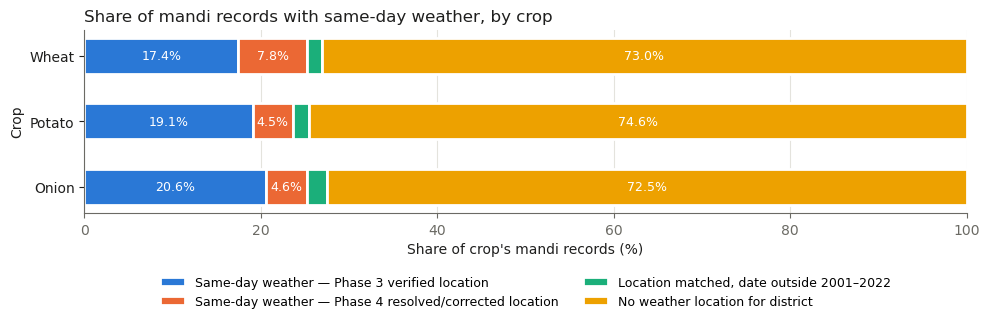

,Same-day weather — Phase 3 verified location,Same-day weather — Phase 4 resolved/corrected location,"Location matched, date outside 2001–2022",No weather location for district
Onion,541412,121172,59230,1902565
Potato,527655,124874,51122,2061336
Wheat,452490,201811,44932,1894534


In [14]:
# Reference categorical palette (fixed slot order) — dataviz skill
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e4e3dd"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": INK, "axes.spines.top": False, "axes.spines.right": False})

def stacked_share(table, title, xlabel, fname, label_min=4.0):
    share = table.div(table.sum(axis=1), axis=0) * 100
    fig, ax = plt.subplots(figsize=(10, 3.6))
    left = np.zeros(len(share))
    for i, col in enumerate(share.columns):
        ax.barh(share.index, share[col], left=left, color=SERIES[i], edgecolor="white", linewidth=2,
                height=0.55, label=col)
        for y, (l, v) in enumerate(zip(left, share[col])):
            if v >= label_min:
                ax.text(l + v / 2, y, f"{v:.1f}%", ha="center", va="center", color="white", fontsize=9)
        left += share[col].to_numpy()
    ax.set_xlim(0, 100); ax.set_xlabel(xlabel); ax.set_ylabel("Crop")
    ax.set_title(title, loc="left", color=INK)
    ax.xaxis.grid(True, color=GRID); ax.set_axisbelow(True)
    ax.legend(ncol=2, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.28), fontsize=9)
    fig.tight_layout(); fig.savefig(FIG / fname, dpi=150, bbox_inches="tight"); plt.show()

counts = {}
for crop in CROPS:
    d = pd.read_parquet(f"Processed_Data/integration/mandi_integrated_{crop.lower()}.parquet",
                        columns=["weather_location_method", "weather_match"])
    m, meth = d["weather_match"].astype(str), d["weather_location_method"].astype(str)
    counts[crop] = {
        "Same-day weather — Phase 3 verified location": int(((m == "exact_district") & (meth == "phase3_verified")).sum()),
        "Same-day weather — Phase 4 resolved/corrected location": int(((m == "exact_district") & (meth != "phase3_verified")).sum()),
        "Location matched, date outside 2001–2022": int((m == "exact_district_outside_weather_window").sum()),
        "No weather location for district": int((m == "no_weather_location").sum()),
    }
weather_tbl = pd.DataFrame(counts).T
stacked_share(weather_tbl, "Share of mandi records with same-day weather, by crop",
              "Share of crop's mandi records (%)", "phase04_weather_match_by_crop.png")
weather_tbl

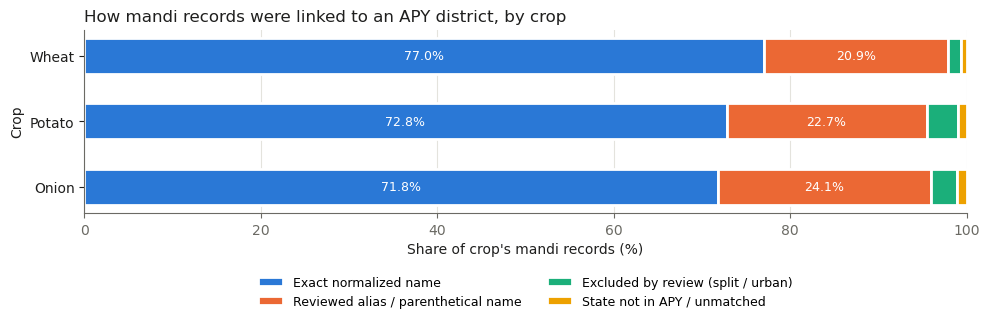

,Exact normalized name,Reviewed alias / parenthetical name,Excluded by review (split / urban),State not in APY / unmatched
crop,,,,
Onion,1883348.0,633657.0,78461.0,28913.0
Potato,2012454.0,627046.0,97226.0,28261.0
Wheat,1997068.0,542157.0,38256.0,16286.0


In [15]:
a = cov[cov["dimension"] == "apy_district_match"].pivot_table(index="crop", columns="value", values="records").fillna(0)
apy_tbl = pd.DataFrame({
    "Exact normalized name": a["exact_normalized"],
    "Reviewed alias / parenthetical name": a["reviewed_alias"] + a["parenthetical_part"],
    "Excluded by review (split / urban)": a["excluded_by_review"],
    "State not in APY / unmatched": a["state_not_in_apy"] + a.get("unmatched", 0),
})
stacked_share(apy_tbl, "How mandi records were linked to an APY district, by crop",
              "Share of crop's mandi records (%)", "phase04_apy_district_match_by_crop.png")
apy_tbl

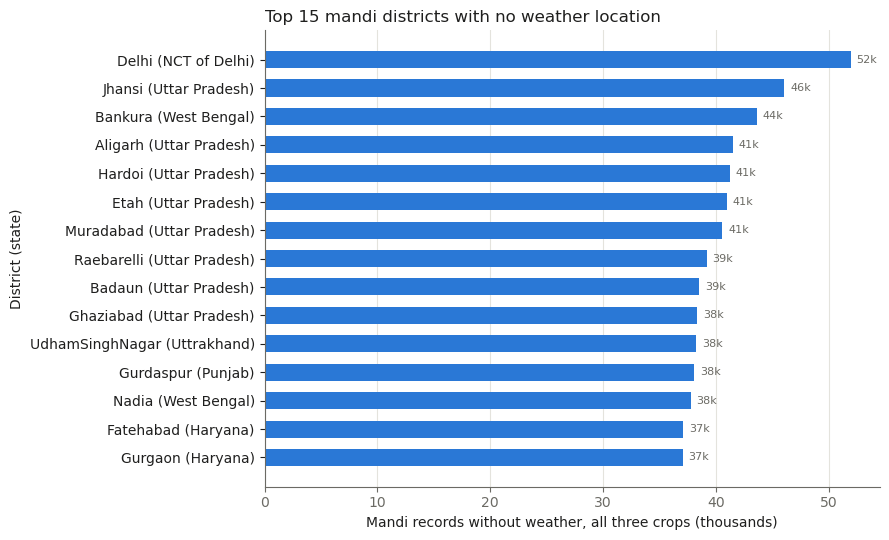

In [16]:
top = (unmatched[unmatched["key_type"] == "weather_location"].groupby(["state", "district"])["records"].sum()
       .sort_values(ascending=False).head(15).iloc[::-1])
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh([f"{d} ({s})" for s, d in top.index], top.values / 1000, color=SERIES[0], height=0.6)
for y, v in enumerate(top.values / 1000):
    ax.text(v + 0.5, y, f"{v:,.0f}k", va="center", fontsize=8, color=MUTED)
ax.set_xlabel("Mandi records without weather, all three crops (thousands)")
ax.set_ylabel("District (state)")
ax.set_title("Top 15 mandi districts with no weather location", loc="left", color=INK)
ax.xaxis.grid(True, color=GRID); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(FIG / "phase04_top_unmatched_weather_districts.png", dpi=150); plt.show()

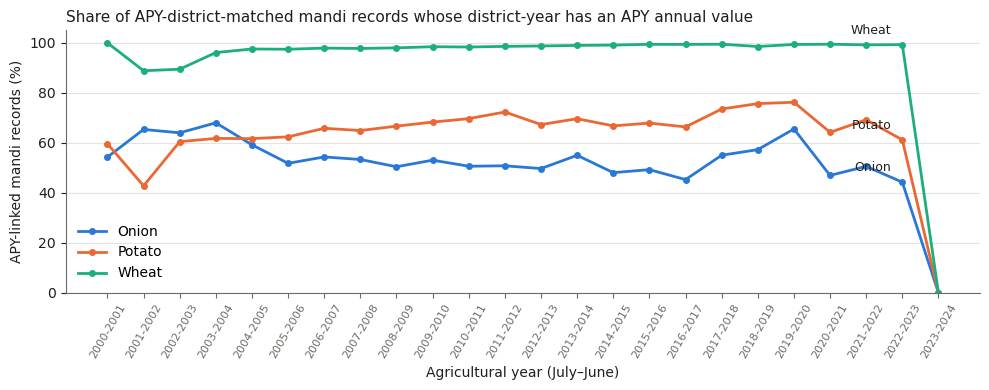

In [17]:
yr = (mandi_apy[mandi_apy["mandi_records"].notna()]
      .assign(linked=lambda d: np.where(d["link_status"] == "mandi_and_apy", d["mandi_records"], 0))
      .groupby(["crop", "apy_year"])[["linked", "mandi_records"]].sum())
yr["share"] = yr["linked"] / yr["mandi_records"] * 100
fig, ax = plt.subplots(figsize=(10, 4))
for i, crop in enumerate(CROPS):
    s = yr.loc[crop]["share"]
    ax.plot(s.index, s.values, color=SERIES[i], linewidth=2, marker="o", markersize=4, label=crop)
    ax.annotate(crop, ("2022-2023", s["2022-2023"]), xytext=(-8, 8), textcoords="offset points",
                ha="right", color=INK, fontsize=9)
ax.set_ylim(0, 105); ax.set_ylabel("APY-linked mandi records (%)")
ax.set_xlabel("Agricultural year (July–June)")
ax.set_title("Share of APY-district-matched mandi records whose district-year has an APY annual value",
             loc="left", color=INK, fontsize=11)
ax.tick_params(axis="x", rotation=60, labelsize=8)
ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower left")
fig.tight_layout(); fig.savefig(FIG / "phase04_apy_link_share_by_year.png", dpi=150); plt.show()

<a id="12"></a>
## 12. Interpretation

- **Nothing was lost or multiplied.** All 7,983,133 mandi records (Onion 2,624,379; Potato 2,764,987; Wheat 2,593,767) appear exactly once in the integrated tables; every left join kept its row count; there are no many-to-many joins.
- **Weather coverage is about a quarter of records** (Onion 25.3%, Potato 23.6%, Wheat 25.2% get same-day weather). This is by design (D-12): weather exists only for the 46 top-volume districts, and records after 2022-12-31 fall outside the weather window. The 10 locations resolved in Phase 4 give a weather location to a further 4.1–8.2% of records per crop (largest for Wheat: Gujarat, Rajasthan and Maharashtra districts).
- **The Ferozpur correction mattered**: without the admin2 check, ~0.8% of Onion and Potato records would have received weather from a point ~159 km away in another district.
- **APY district linkage is high** (≈96% of Onion/Potato and ≈98% of Wheat records have an APY district), but **APY annual values exist for far fewer Onion records (47%)** than Potato (62%) or Wheat (94%): APY reports Onion for fewer district-years than mandis trade it. This is a real coverage limit for Phase 10's Onion supply modelling, not an integration error.
- **The APY share drops to 0 in 2023-2024** because APY ends with 2022-2023 — that year is correctly left unlinked rather than filled.
- **Agri Market cross-check**: 96.6% of in-coverage Agri Market Wheat rows match a national mandi Wheat record on (district, market, variety, date), and **100% of matched rows have identical prices and arrivals**. The regional dataset is therefore almost certainly drawn from the same Agmarknet feed — it confirms the integration keys are consistent, but it is **not independent validation** of mandi values.
- **Duplicates are rare** (≈0.05% of records share a key); most are exact copies, 68 / 165 / 106 rows (Onion / Potato / Wheat) conflict. They are flagged (`dup_type`) for Phase 5.

<a id="13"></a>
## 13. Limitations and Unresolved Issues

1. **No weather for ~73–75% of records** (districts outside the 46 representative locations, plus 2023–24 dates). No proxy matching was done; extending coverage needs verified coordinates for more districts (new collection work).
2. **District-level representative weather** (A-10): one point per district; intra-district variation is not captured.
3. **Excluded districts**: Burdwan, Kanpur, Bangalore and Tripura's South/West District (splits/reorganisations), plus Delhi, Mumbai, Kolkata, Hyderabad, Chennai (no APY rows) and Goa/A&N/Lakshadweep (state absent from APY for these crops) have no APY link. A time-aware split mapping could recover some later.
4. **APY uses current district names for all years**, but split districts' earlier totals include areas later moved elsewhere — a source property that cross-year comparisons must respect.
5. **18 APY district-years** have several seasons but no `Total` row; their annual value is left missing rather than summed (Whole Year may overlap other seasons).
6. **Agricultural-year mapping** is definitional (July–June); stored produce sold after June is labelled with the next agricultural year.
7. **Agri Market is not independent** of mandi data (identical values), so it cannot validate mandi prices; Onion and Potato still have no regional cross-check.
8. **Data-quality anomalies are preserved for Phase 5**: zero prices, min > max rows, the 339 conflicting and 3,520 exact-duplicate rows, and the one Agri Market arrivals value with a thousands separator (`1,050.00`, parsed as 1050).
9. **Aliases rely on documented domain knowledge** (official renames, headquarters towns) checked against APY's official names; they were not cross-checked against an external gazetteer beyond the Open-Meteo geocoder evidence.

<a id="14"></a>
## 14. Completion Summary and Phase 5 Handoff

**Phase 4 status: completed** — pipeline, outputs, audits, notebook validation checks and the automated test suite all pass (see Section 10).

**Phase 5 (Data Cleaning) receives**:
- `Processed_Data/integration/mandi_integrated_{onion,potato,wheat}.parquet` — row-preserving, with `source_row`, `dup_key_count`/`dup_type`, standardized names, APY keys, market codes and same-day weather.
- `weather_daily_panel.parquet`, `apy_season.csv`, `apy_annual.csv`, `mandi_apy_district_year.csv`, `district_crosswalk.csv`, `agrimarket_wheat_crosscheck.csv`.
- Audit tables in `Processed_Data/integration/audit/`.

**Phase 5 must decide (documented, not blind)**: treatment of exact vs conflicting duplicate keys, zero-price and min > max rows, missing modal prices, and outliers — using `source_row` to stay traceable to the raw files. It must **not** fill missing weather with zeros or repeat APY annual values onto daily rows as if they were daily observations.